## 1. Setup and experiment design
Goal: measure whether training on the ADASYN-resampled data improves Logistic Regression and the two Decision Trees. Each model is retrained with its **original hyperparameters** on `adasyn_training_data.csv` and evaluated on the **original, untouched test set**. The same three models trained on the original data are the baseline.

In [1]:
import hashlib
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

TARGET = "preterm_birth"

# ADASYN already balances the classes, so class_weight="balanced" would correct the
# imbalance a second time. Justified in Step 5.
DROP_CLASS_WEIGHT_FOR_ADASYN = True

## 2. Loading the data and the saved models
A fingerprint of the test set is stored now to prove at the end that it was never modified.

In [2]:
def fingerprint(df):
    return hashlib.sha256(pd.util.hash_pandas_object(df, index=True).values.tobytes()).hexdigest()

def same_values(a, b):
    """True if two tables hold the same values (tiny float rounding from CSV files is ignored)."""
    try:
        pd.testing.assert_frame_equal(a.reset_index(drop=True), b.reset_index(drop=True), check_dtype=False)
        return True
    except AssertionError:
        return False

train = pd.read_csv("train_preprocessed.csv")
test = pd.read_csv("test_preprocessed.csv")
adasyn = pd.read_csv("adasyn_training_data.csv")
test_hash_before = fingerprint(test)

X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]
X_adasyn, y_adasyn = adasyn.drop(columns=TARGET), adasyn[TARGET]

lr = joblib.load("logistic_regression_model.pkl")      # saved with joblib, despite the .pkl name
dt_base = joblib.load("baseline_decision_tree.joblib")
dt_reg = joblib.load("regularized_decision_tree.joblib")
baseline_models = {"Logistic Regression": lr,
                   "Decision Tree (baseline)": dt_base,
                   "Decision Tree (regularized)": dt_reg}

print("Original train:", train.shape, "| ADASYN train:", adasyn.shape, "| Test:", test.shape)

Original train: (8000, 19) | ADASYN train: (14506, 19) | Test: (2000, 19)


## 3. Verifying the same preprocessing pipeline and original split
Before comparing results we check that all files come from the same preprocessing and the same train/test split.

In [3]:
feat = list(lr.feature_names_in_)
for name, m in baseline_models.items():
    print(name, "- same 18 features:", list(m.feature_names_in_) == feat)
print("ADASYN file - same features:", list(X_adasyn.columns) == feat)

# The ADASYN file must start with the original training rows (synthetic rows are appended)
print("ADASYN file starts with the original training set:", same_values(adasyn.iloc[:len(train)], train))

print("Class counts, original train:", y_train.value_counts().sort_index().to_dict())
print("Class counts, ADASYN train:  ", y_adasyn.value_counts().sort_index().to_dict())
print("Test preterm rate:", round(y_test.mean(), 4))

# Do the saved models match what the original training data produces?
repro_lr = np.allclose(clone(lr).fit(X_train, y_train).coef_, lr.coef_)
repro_dt = (clone(dt_base).fit(X_train, y_train).predict(X_test) == dt_base.predict(X_test)).all()
print("Saved Logistic Regression reproduced:", repro_lr, "| saved baseline Decision Tree reproduced:", repro_dt)

Logistic Regression - same 18 features: True
Decision Tree (baseline) - same 18 features: True
Decision Tree (regularized) - same 18 features: True
ADASYN file - same features: True
ADASYN file starts with the original training set: True
Class counts, original train: {0: 7150, 1: 850}
Class counts, ADASYN train:   {0: 7150, 1: 7356}
Test preterm rate: 0.106
Saved Logistic Regression reproduced: True | saved baseline Decision Tree reproduced: False


## 4. Evaluation metrics
The positive class is preterm birth (1). Metrics: accuracy, precision, recall, F1-score and ROC-AUC (computed from predicted probabilities), plus the confusion matrix counts (TN, FP, FN, TP). The decision threshold is the default 0.5.

In [4]:
def evaluate(model, X, y):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred),
            "F1-score": f1_score(y, pred),
            "ROC-AUC": roc_auc_score(y, proba),
            "TN": tn, "FP": fp, "FN": fn, "TP": tp}

## 5. Retraining the existing models on the ADASYN data
Each saved model is cloned, which copies its hyperparameters but not its fitted state, and then fitted on the ADASYN training set.

**Class weights.** The regularized Decision Tree was originally trained with `class_weight="balanced"`. After ADASYN the classes are almost equal, so the balanced weights are about 1 and would only double-correct the imbalance. For the ADASYN version this setting is therefore removed (`class_weight=None`). All other hyperparameters stay identical.

In [5]:
w = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_adasyn)
print("Balanced class weights on the ADASYN data (term, preterm):", w.round(3))

adasyn_models = {}
for name, m in baseline_models.items():
    new = clone(m)
    if DROP_CLASS_WEIGHT_FOR_ADASYN and new.get_params().get("class_weight") is not None:
        new.set_params(class_weight=None)
    adasyn_models[name] = new.fit(X_adasyn, y_adasyn)
    print("Retrained:", name)

Balanced class weights on the ADASYN data (term, preterm): [1.014 0.986]
Retrained: Logistic Regression
Retrained: Decision Tree (baseline)
Retrained: Decision Tree (regularized)


## 6. Evaluation on the original, untouched test set
Baseline models (trained on the original data) and ADASYN models are evaluated on exactly the same 2,000 test records.

In [6]:
rows = []
for name in baseline_models:
    rows.append({"Model": name, "Training data": "Original", **evaluate(baseline_models[name], X_test, y_test)})
    rows.append({"Model": name, "Training data": "ADASYN", **evaluate(adasyn_models[name], X_test, y_test)})

results = pd.DataFrame(rows)
score_cols = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
results[score_cols] = results[score_cols].round(4)
results.to_csv("adasyn_evaluation_results.csv", index=False)
results

,Model,Training data,Accuracy,Precision,Recall,F1-score,ROC-AUC,TN,FP,FN,TP
0,Logistic Regression,Original,0.9075,0.7143,0.2123,0.3273,0.7427,1770,18,167,45
1,Logistic Regression,ADASYN,0.7665,0.2465,0.5849,0.3469,0.7356,1409,379,88,124
2,Decision Tree (baseline),Original,0.8480,0.2982,0.3208,0.3091,0.6153,1628,160,144,68
3,Decision Tree (baseline),ADASYN,0.8035,0.2181,0.3302,0.2627,0.5943,1537,251,142,70
4,Decision Tree (regularized),Original,0.7930,0.2694,0.5566,0.3631,0.7130,1468,320,94,118
5,Decision Tree (regularized),ADASYN,0.8345,0.3111,0.4623,0.3719,0.6936,1571,217,114,98


In [7]:
metrics = ["Precision", "Recall", "F1-score", "ROC-AUC"]
base = results[results["Training data"] == "Original"].set_index("Model")[metrics]
ada = results[results["Training data"] == "ADASYN"].set_index("Model")[metrics]
(ada - base).round(4)    # positive = improved by ADASYN

,Precision,Recall,F1-score,ROC-AUC
Model,,,,
Logistic Regression,-0.4678,0.3726,0.0196,-0.0071
Decision Tree (baseline),-0.0801,0.0094,-0.0464,-0.0210
Decision Tree (regularized),0.0417,-0.0943,0.0088,-0.0194


## 7. Confusion matrices
Top row: models trained on the original data. Bottom row: models trained on the ADASYN data. All are evaluated on the same test set.


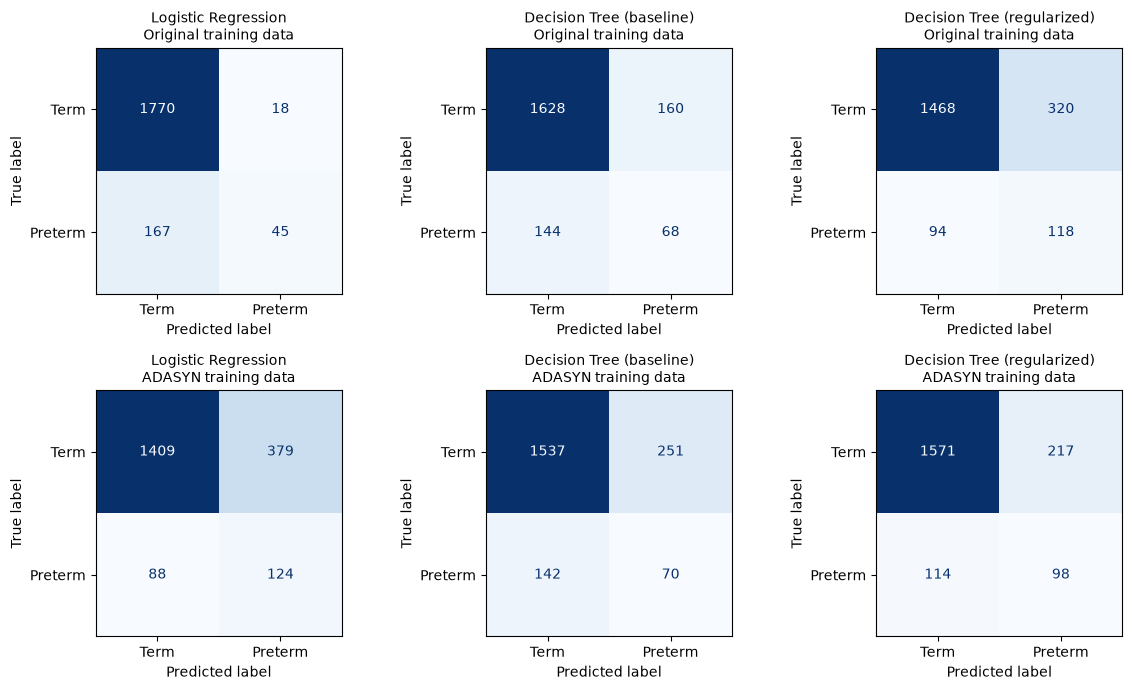

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for j, name in enumerate(baseline_models):
    for i, (label, models) in enumerate([("Original training data", baseline_models),
                                         ("ADASYN training data", adasyn_models)]):
        ConfusionMatrixDisplay.from_estimator(models[name], X_test, y_test,
                                              display_labels=["Term", "Preterm"],
                                              cmap="Blues", colorbar=False, ax=axes[i, j])
        axes[i, j].set_title(f"{name}\n{label}", fontsize=10)
plt.tight_layout()
plt.savefig("adasyn_confusion_matrices.png", dpi=200)
plt.show()

## 8. Methodology checklist
Each item is verified by code and saved to `adasyn_methodology_checklist.csv`.

In [9]:
same_params = all(
    {k: v for k, v in baseline_models[n].get_params().items() if k != "class_weight"} ==
    {k: v for k, v in adasyn_models[n].get_params().items() if k != "class_weight"}
    for n in baseline_models)

# How far does the refitted baseline tree differ from the saved one?
n_diff = int((clone(dt_base).fit(X_train, y_train).predict(X_test) != dt_base.predict(X_test)).sum())
repro_dt_ok = n_diff / len(X_test) <= 0.01      # tolerance: 1% of the test predictions

checks = [
 ("Same preprocessing pipeline: 18 features, same names and order as the saved models",
  list(X_adasyn.columns) == feat and list(X_test.columns) == feat),
 ("Same original train split: the ADASYN file starts with the original training set",
  same_values(adasyn.iloc[:len(train)], train)),
 ("Test set untouched: not resampled, fingerprint unchanged",
  fingerprint(test) == test_hash_before),
 ("Same hyperparameters as the existing models (except class_weight on the regularized tree)",
  same_params),
 (f"Saved models reproduce when refitted: Logistic Regression exact; baseline tree within tolerance "
  f"({n_diff} of {len(X_test)} test predictions differ)",
  bool(repro_lr and repro_dt_ok)),
]
checklist = pd.DataFrame(checks, columns=["Check", "Passed"])
checklist["Passed"] = checklist["Passed"].map({True: "Yes", False: "No"})
checklist.to_csv("adasyn_methodology_checklist.csv", index=False)
checklist

,Check,Passed
0,"Same preprocessing pipeline: 18 features, same...",Yes
1,Same original train split: the ADASYN file sta...,Yes
2,"Test set untouched: not resampled, fingerprint...",Yes
3,Same hyperparameters as the existing models (e...,Yes
4,Saved models reproduce when refitted: Logistic...,Yes


### Note on the "Saved models reproduce" check

Logistic Regression was reproduced exactly. The saved baseline Decision Tree (unrestricted, depth 37) was reproduced approximately: when refitted on the same training data, 13 of the 2,000 test predictions (0.65%) differ. This is expected for a very deep tree, where tiny numeric differences (CSV rounding, tie-breaking between equally good splits, library version) can change a split deep in the tree. It does not indicate a different training set or split, since Logistic Regression and the data checks all match. The saved model is used unchanged in the evaluation.

## 9. Interpretation

**Effect of ADASYN.** ADASYN changed the recall/precision trade-off but did not improve the models' ability to discriminate. ROC-AUC decreased slightly for all three models (Logistic Regression 0.743 to 0.736, baseline tree 0.615 to 0.594, regularized tree 0.713 to 0.694).

**Logistic Regression.** Recall increased from 0.212 to 0.585 (45 to 124 of 212 preterm cases detected), but precision fell from 0.714 to 0.247 (false alarms rose from 18 to 379). F1 improved only marginally (0.327 to 0.347).

**Baseline Decision Tree.** ADASYN did not help: F1 fell from 0.309 to 0.263 and ROC-AUC from 0.615 to 0.594. The unrestricted tree (depth 37) memorizes the training data, including the synthetic records.

**Regularized Decision Tree.** The ADASYN version was trained without class_weight="balanced", because ADASYN already balances the classes. Its comparison therefore contrasts class weighting with oversampling, not oversampling alone. Recall decreased (0.557 to 0.462) while precision increased (0.269 to 0.311), with similar F1 (0.363 and 0.372).

**Best model.** Original Logistic Regression has the best ROC-AUC (0.743) and precision but detects only 21% of preterm births at the 0.5 threshold. If the goal is screening, Logistic Regression with ADASYN (recall 0.585) or the regularized tree (recall 0.557 or 0.462) detect substantially more cases, at the price of many false alarms.

**Limitations.** The test set has only 212 preterm cases, so small differences are within noise. ADASYN creates fractional values in binary and one-hot columns. About a third of test rows have an identical row in the training set, so scores may be optimistic. Results use one split and the default 0.5 threshold.